# 2. Probabilistic Models and RNNs

Practice for module 2: joint vs conditional probabilities from counts, the chain rule on a probability
tree, a bigram language model, an autoregressive model of tiny binary images, and a character-level RNN
trained with backpropagation through time, including the vanishing gradient over long sequences.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 2.1 Joint vs conditional probability from counts

Joint `P(weather, umbrella)` divides by the global total; conditional `P(umbrella | weather)` divides by
the local count of rows where the condition holds.

In [2]:
weather = rng.choice(["rain", "sun"], size=1000, p=[0.3, 0.7])
umbrella = np.where(weather == "rain", rng.random(1000) < 0.8, rng.random(1000) < 0.1)

total = len(weather)
n_rain = (weather == "rain").sum()
n_rain_umb = ((weather == "rain") & umbrella).sum()

P_rain = n_rain / total
P_joint = n_rain_umb / total                  # global denominator
P_cond = n_rain_umb / n_rain                  # local denominator
print(f"P(rain)              = {P_rain:.3f}")
print(f"P(rain, umbrella)    = {n_rain_umb}/{total} = {P_joint:.3f}")
print(f"P(umbrella | rain)   = {n_rain_umb}/{n_rain} = {P_cond:.3f}")
print(f"chain rule: P(rain)·P(umbrella|rain) = {P_rain * P_cond:.3f} == joint")

# P(umbrella | weather) with `weather` unbound is a whole table (one distribution per value)
for w in ["rain", "sun"]:
    print(f"P(umbrella=True | weather={w}) = {umbrella[weather == w].mean():.3f}")

P(rain)              = 0.277
P(rain, umbrella)    = 227/1000 = 0.227
P(umbrella | rain)   = 227/277 = 0.819
chain rule: P(rain)·P(umbrella|rain) = 0.227 == joint
P(umbrella=True | weather=rain) = 0.819
P(umbrella=True | weather=sun) = 0.109


## 2.2 Probability tree: product along a path = joint probability

In [3]:
tree = {"rain": (0.3, {"umbrella": 0.8, "no umbrella": 0.2}),
        "sun":  (0.7, {"umbrella": 0.1, "no umbrella": 0.9})}
paths = {(w, u): pw * pu for w, (pw, kids) in tree.items() for u, pu in kids.items()}
for path, p in paths.items():
    print(f"{' -> '.join(path):25s} {p:.2f}")
print("leaves sum to", sum(paths.values()))

rain -> umbrella          0.24
rain -> no umbrella       0.06
sun -> umbrella           0.07
sun -> no umbrella        0.63
leaves sum to 1.0


## 2.3 Bigram language model

Chain rule with a 1-word context: `P(w1..wn) ≈ Π P(wi | wi-1)`. Each factor is a local count ratio.

In [4]:
corpus = """the cat sat on the mat . the dog sat on the rug . the cat saw the dog .
the dog saw the cat . a cat sat on a rug . the dog ate the food .""".split()
bigrams = Counter(zip(corpus[:-1], corpus[1:]))
unigrams = Counter(corpus[:-1])
vocab = sorted(set(corpus))

def p_next(w, prev): return bigrams[(prev, w)] / unigrams[prev]

def sentence_prob(s):
    words = ["."] + s.split()
    return np.prod([p_next(w, p) for p, w in zip(words[:-1], words[1:])])

for s in ["the cat sat on the mat .", "the dog sat on the mat .", "mat the on sat cat the ."]:
    print(f"P({s!r}) = {sentence_prob(s):.5f}")

def generate(n=12):
    w, out = ".", []
    for _ in range(n):
        probs = np.array([p_next(v, w) for v in vocab])
        w = rng.choice(vocab, p=probs); out.append(w)
    return " ".join(out)

print("\nsamples:"); [print(" ", generate()) for _ in range(3)]

P('the cat sat on the mat .') = 0.00800
P('the dog sat on the mat .') = 0.00533
P('mat the on sat cat the .') = 0.00000

samples:
  a rug . the cat saw the cat . the dog ate
  the mat . the dog sat on the dog sat on the
  the mat . the dog saw the cat saw the cat sat


[None, None, None]

## 2.4 Autoregressive model of tiny images

6×6 binary images, each with one full horizontal or vertical line. A full joint table would need
`2^36 ≈ 7·10^10` entries. With the chain rule each pixel is predicted only from already generated
pixels, summarized by a small context (left, up, first pixel of this row, anything drawn in earlier
rows, is the row above full, anything drawn yet). The conditionals are estimated by counting, and images are sampled one pixel at a time.

possible 6x6 binary images: 68719476736


log P(training-like image) = -2.52, log P(random noise) = -78.18


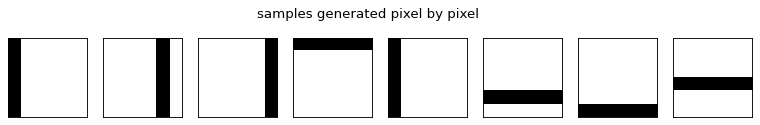

In [5]:
S = 6
def make_img():
    im = np.zeros((S, S), int); k = rng.integers(S)
    if rng.random() < 0.5: im[k, :] = 1
    else:                  im[:, k] = 1
    return im

def context(im, i, j):
    left = im[i, j - 1] if j else 0
    up = im[i - 1, j] if i else 0
    row_first = im[i, 0] if j else 0
    prev_rows = int(im[:i].any())
    above_full = int(i > 0 and im[i - 1].all())
    any_on = int(im.ravel()[:i * S + j].any())
    return left, up, row_first, prev_rows, above_full, any_on

data = np.stack([make_img() for _ in range(3000)])
print("possible 6x6 binary images:", 2 ** (S * S))

counts = np.full((S, S) + (2,) * 7, 0.1)         # position, 6 context bits, value; small additive smoothing
for im in data:
    for i in range(S):
        for j in range(S):
            counts[(i, j, *context(im, i, j), im[i, j])] += 1
P1 = counts[..., 1] / counts.sum(-1)              # P(pixel = 1 | position, context)

def sample_img():
    im = np.zeros((S, S), int)
    for i in range(S):
        for j in range(S):
            im[i, j] = rng.random() < P1[(i, j, *context(im, i, j))]
    return im

def log_prob(im):                                 # chain rule: sum of log conditionals
    lp = 0
    for i in range(S):
        for j in range(S):
            p = P1[(i, j, *context(im, i, j))]; lp += np.log(p if im[i, j] else 1 - p)
    return lp

print(f"log P(training-like image) = {log_prob(data[0]):.2f}, log P(random noise) = {log_prob(rng.integers(0, 2, (S, S))):.2f}")
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for a in axes:
    a.imshow(sample_img(), cmap="gray_r", vmin=0, vmax=1); a.set_xticks([]); a.set_yticks([])
plt.suptitle("samples generated pixel by pixel"); plt.show()

## 2.5 Character-level RNN trained with BPTT

`h_t = tanh(W_xh x_t + W_hh h_{t-1} + b)`, `y_t = W_hy h_t`. The hidden state carries past context, so the
output depends on all previous inputs (unlike an MLP). Generation is autoregressive: each sampled
character is fed back as the next input.

before training: 'hlhh.ononwreeednnlwde o deenondrlohdodlol'


after training:  'hello world. hello rnn. hello world. hell'


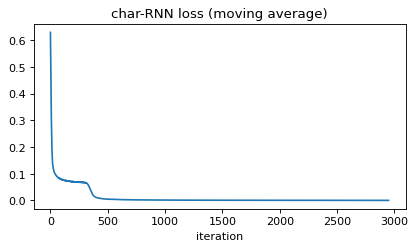

In [6]:
text = "hello world. hello rnn. " * 20
chars = sorted(set(text)); V = len(chars)
ix = {c: i for i, c in enumerate(chars)}
data_ix = np.array([ix[c] for c in text])

Hd = 32
Wxh = rng.normal(0, 0.1, (Hd, V)); Whh = rng.normal(0, 0.1, (Hd, Hd)); Why = rng.normal(0, 0.1, (V, Hd))
bh, by = np.zeros(Hd), np.zeros(V)
params = [Wxh, Whh, Why, bh, by]
mem = [np.zeros_like(p) for p in params]

def step_loss(inputs, targets, hprev):
    xs, hs, ps, loss = {}, {-1: hprev}, {}, 0
    for t in range(len(inputs)):
        xs[t] = np.eye(V)[inputs[t]]
        hs[t] = np.tanh(Wxh @ xs[t] + Whh @ hs[t - 1] + bh)
        y = Why @ hs[t] + by
        ps[t] = np.exp(y - y.max()); ps[t] /= ps[t].sum()
        loss -= np.log(ps[t][targets[t]])
    grads = [np.zeros_like(p) for p in params]
    dWxh, dWhh, dWhy, dbh, dby = grads
    dh_next = np.zeros(Hd)
    for t in reversed(range(len(inputs))):          # backprop through time
        dy = ps[t].copy(); dy[targets[t]] -= 1      # prediction - target
        dWhy += np.outer(dy, hs[t]); dby += dy
        dh = Why.T @ dy + dh_next
        draw = (1 - hs[t] ** 2) * dh
        dbh += draw; dWxh += np.outer(draw, xs[t]); dWhh += np.outer(draw, hs[t - 1])
        dh_next = Whh.T @ draw
    for g in grads: np.clip(g, -5, 5, out=g)
    return loss / len(inputs), grads, hs[len(inputs) - 1]

def sample(seed_char, n):
    h, x, out = np.zeros(Hd), ix[seed_char], seed_char
    for _ in range(n):
        h = np.tanh(Wxh[:, x] + Whh @ h + bh)
        p = np.exp(Why @ h + by); p /= p.sum()
        x = rng.choice(V, p=p); out += chars[x]      # one-to-many: output fed back as input
    return out

seq, lr, losses, h, pos = 16, 0.1, [], np.zeros(Hd), 0
print("before training:", repr(sample("h", 40)))
for it in range(3000):
    if pos + seq + 1 >= len(data_ix): pos, h = 0, np.zeros(Hd)
    loss, grads, h = step_loss(data_ix[pos:pos + seq], data_ix[pos + 1:pos + seq + 1], h)
    for p, g, m in zip(params, grads, mem):           # Adagrad
        m += g * g; p -= lr * g / np.sqrt(m + 1e-8)
    losses.append(loss); pos += seq
print("after training: ", repr(sample("h", 40)))

plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, "valid"))
plt.title("char-RNN loss (moving average)"); plt.xlabel("iteration"); plt.show()

## 2.6 Vanishing gradient through time

The gradient from step T back to step T-k is a product of k Jacobians `diag(1-h²)·W_hh`.
Its norm shrinks roughly geometrically, so early inputs barely affect learning: the long-range
dependency problem.

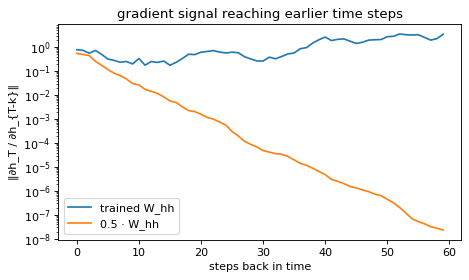

In [7]:
def grad_through_time(Whh, T=60):
    h, hs = np.zeros(Hd), []
    for t in range(T):
        h = np.tanh(Wxh[:, rng.integers(V)] + Whh @ h + bh); hs.append(h)
    g, norms = np.ones(Hd) / np.sqrt(Hd), []
    for h in reversed(hs):
        g = Whh.T @ ((1 - h ** 2) * g); norms.append(np.linalg.norm(g))
    return norms

plt.figure(figsize=(6.5, 3.5))
plt.semilogy(grad_through_time(Whh), label="trained W_hh")
plt.semilogy(grad_through_time(0.5 * Whh), label="0.5 · W_hh")
plt.xlabel("steps back in time"); plt.ylabel("‖∂h_T / ∂h_{T-k}‖"); plt.legend()
plt.title("gradient signal reaching earlier time steps"); plt.show()

## 2.7 Encoder-decoder for variable-length sequences

The encoder RNN folds a sequence of any length into one fixed-size hidden state; a decoder RNN would
unroll from it into a sequence of a different length (e.g. a translation).

In [8]:
for word in ["he", "hello", "hello world. hello rnn."]:
    h = np.zeros(Hd)
    for c in word:
        h = np.tanh(Wxh[:, ix[c]] + Whh @ h + bh)
    print(f"{word!r:15s} length {len(word):2d} -> context vector shape {h.shape}")

'he'            length  2 -> context vector shape (32,)
'hello'         length  5 -> context vector shape (32,)
'hello world. hello rnn.' length 23 -> context vector shape (32,)
